# Diffusion Models

This notebook has a minimal smoke test for loading the main diffusion backbones and generating a few example images with standard sampling.

For details about the model configurations and sampling pipeline, see the `src/model_utils.py` file.

In [1]:
from pathlib import Path

from IPython.display import display
from PIL import Image

from zigzag_project.model_utils import (
    DREAM_SHARPER,
    SDXL,
    free_pipeline,
    generate_images_standard,
    list_model_configs,
    load_pipeline_standard,
)

OUTPUT_DIR = Path.cwd().parent / "outputs" / "smoke_test_examples"
SEED = 42


c:\Users\radud\OneDrive\Desktop\Uni Stuff\Master\GM\generative-modelling\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.


# Model Configurations

In [2]:
list_model_configs()

{'sdxl': {'model_id': 'stabilityai/stable-diffusion-xl-base-1.0',
  'num_inference_steps': 50,
  'guidance_scale': 5.5,
  'height': 1024,
  'width': 1024},
 'dreamshaper-xl-v2-turbo': {'model_id': 'Lykon/dreamshaper-xl-v2-turbo',
  'num_inference_steps': 4,
  'guidance_scale': 3.5,
  'height': 1024,
  'width': 1024}}

# Example Prompts

In [3]:
example_prompts = [
    "An elephant in a room full of glassware.",
    # "A dog buying groceries.",
    # "A heart-shaped light blue bomb that explodes inside a pancake."
]

# SDXL Example

### Load the Model

In [4]:
pipeline_sdxl = load_pipeline_standard(SDXL)

c:\Users\radud\OneDrive\Desktop\Uni Stuff\Master\GM\generative-modelling\.venv\lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\radud\.cache\huggingface\hub\models--stabilityai--stable-diffusion-xl-base-1.0. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading pipeline components...: 100%|██████████| 

### Generate Images

In [5]:
result_sdxl = generate_images_standard(
    pipeline_sdxl,
    example_prompts,
    SDXL,
    seed=SEED,
    output_dir=OUTPUT_DIR,
)

result_sdxl


100%|██████████| 50/50 [19:50<00:00, 23.81s/it]


[WindowsPath('c:/Users/radud/OneDrive/Desktop/Uni Stuff/Master/GM/generative-modelling/outputs/smoke_test_examples/sdxl_000_20260525_133959.png')]

### Display One Example

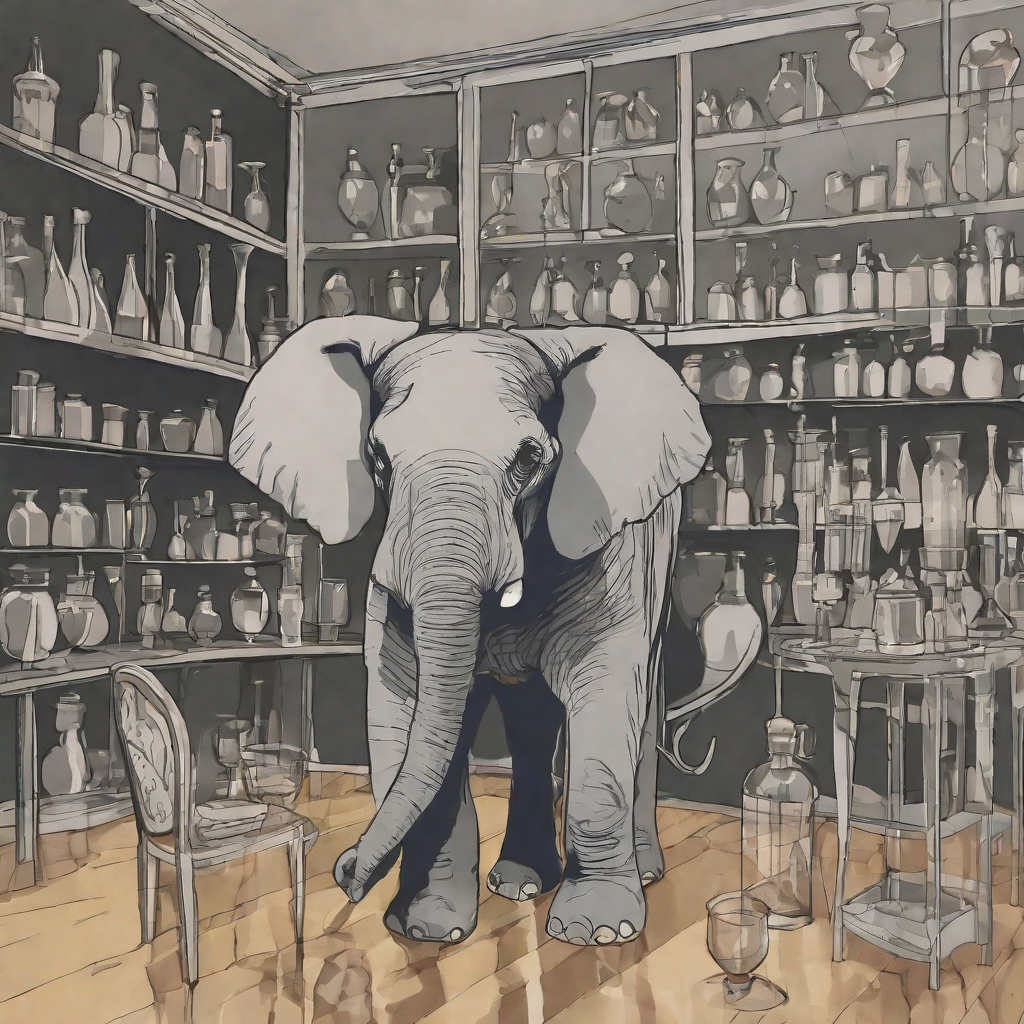

In [9]:
display(Image.open(result_sdxl[0]))

### Free Memory Before Loading Another Model

In [1]:
free_pipeline(pipeline_sdxl)
pipeline_sdxl = None

NameError: name 'free_pipeline' is not defined

# DreamSharper XL Turbo Example

### Load the Model

In [ ]:
pipeline_dream_sharper = load_pipeline_standard(DREAM_SHARPER)

### Generate Images

In [ ]:
result_dream_sharper = generate_images_standard(
    pipeline_dream_sharper,
    example_prompts,
    DREAM_SHARPER,
    seed=SEED,
    output_dir=OUTPUT_DIR,
)

result_dream_sharper


### Display One Example

In [ ]:
display(Image.open(result_dream_sharper[0]))

### Free Memory Before Loading Another Model

In [ ]:
free_pipeline(pipeline_dream_sharper)
pipeline_dream_sharper = None